# Kelly 仓位路径仿真

偶数赔率掷硬币默认参数：$p=0.53$，则 $f^*=0.06$，$f_c\approx 0.1197$。

核心接口：`plot_f(f)`。传入任意仓位 $f\in(0,1)$，画出一条财富路径 $X_n$（对数纵轴），以及从当前局往后的 $\sup_{k\ge n} X_k$ 和 $\inf_{k\ge n} X_k$。这两条阶梯在 $n\to\infty$ 处的极限分别是 $\limsup X_n$ 与 $\liminf X_n$。


## 0. 配置与工具函数

In [1]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib import font_manager

# 中文字体
_CJK_CANDIDATES = [
    "/usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc",
    "/usr/share/fonts/opentype/noto/NotoSerifCJK-Regular.ttc",
    "/usr/share/fonts/noto-cjk/NotoSansCJK-Regular.ttc",
]
_CJK_PATH = next((p for p in _CJK_CANDIDATES if Path(p).exists()), None)
if _CJK_PATH:
    font_manager.fontManager.addfont(_CJK_PATH)
    _CJK_NAME = font_manager.FontProperties(fname=_CJK_PATH).get_name()
    plt.rcParams["font.family"] = _CJK_NAME
    plt.rcParams["font.sans-serif"] = [_CJK_NAME]
plt.rcParams["axes.unicode_minus"] = False

In [2]:
%matplotlib inline

In [3]:
P = 0.53
F_STAR = P - (1.0 - P)  # 0.06
F_C = 0.1197
X0 = 1.0
N_LONG = 10_000
N_PATHS = 40
SEED = 42

print(f"p={P}, f*={F_STAR}, f_c≈{F_C}")

p=0.53, f*=0.06000000000000005, f_c≈0.1197


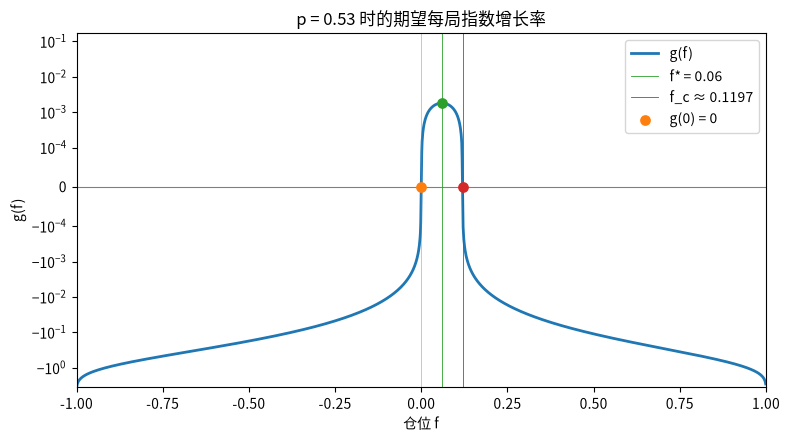

In [4]:
def g_vec(f, p=P):
    return p * np.log(1.0 + f) + (1.0 - p) * np.log(1.0 - f)

# 横轴显示 [-1,1]；采样用开区间，因 f=±1 时 ln 无定义
fs = np.linspace(-0.999, 0.999, 2000)  # 开区间 (-1,1)，端点 ln 无定义
gs = g_vec(fs)
g_star = g_vec(F_STAR)
g_c = g_vec(F_C)  # ≈ 0
g_0 = g_vec(0.0)  # = 0

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(fs, gs, color="C0", lw=2, label="g(f)")
ax.axhline(0.0, color="gray", lw=0.8)
ax.axvline(0.0, color="gray", lw=0.6, alpha=0.5)
ax.axvline(F_STAR, color="C2", lw=0.6, label=f"f* = {F_STAR:.2f}")
ax.axvline(F_C, color="C3", lw=0.6, label=f"f_c ≈ {F_C}")

ax.scatter([0.0], [g_0], color="C1", s=45, zorder=3, label="g(0) = 0")
ax.scatter([F_STAR], [g_star], color="C2", s=45, zorder=3)
ax.scatter([F_C], [g_c], color="C3", s=45, zorder=3)

ax.set_xlim(-1.0, 1.0)
ax.set_yscale("symlog", linthresh=1e-4)  # g(f) 过零且为负，用对称对数
ax.set_xlabel("仓位 f")
ax.set_ylabel("g(f)")
ax.set_title(f"p = {P} 时的期望每局指数增长率")
ax.legend()
fig.tight_layout()
plt.show()


In [5]:
def g(f, p=P):
    """期望每局对数增长率。"""
    if not (0.0 < f < 1.0):
        raise ValueError("偶数赔率下需要 0 < f < 1")

    q = 1.0 - p
    return float(p * np.log(1.0 + f) + q * np.log(1.0 - f))


def simulate(f, *, p=P, n=N_LONG, x0=X0, seed=SEED):
    """模拟一条财富路径，返回 shape=(n+1,) 的数组。"""
    rng = np.random.default_rng(seed)

    wins = rng.random(n) < p
    factors = np.where(wins, 1.0 + f, 1.0 - f)

    w = np.empty(n + 1, dtype=float)
    w[0] = x0
    w[1:] = x0 * np.cumprod(factors)

    return w


def plot_f(f, *, p=P, n=N_LONG, x0=X0, seed=SEED):
    """画一条财富路径，以及从当前局往后的尾巴 sup / inf。

    U_n = sup_{k≥n} X_k  单调不增，n→∞ 时的极限是 limsup
    L_n = inf_{k≥n} X_k  单调不减，n→∞ 时的极限是 liminf
    有限样本的右端尾巴只剩 X_n，所以两条阶梯在最后一个点重合。
    """
    gf = g(f, p)

    w = simulate(f, p=p, n=n, x0=x0, seed=seed)
    t = np.arange(n + 1)

    # 从右往左累积，再翻回来：时刻 n 起剩余路径的 sup / inf
    rev = w[::-1]
    tail_sup = np.maximum.accumulate(rev)[::-1]
    tail_inf = np.minimum.accumulate(rev)[::-1]

    fig, ax = plt.subplots(figsize=(10, 5))

    ax.plot(
        t, w, color="C0", lw=1,
        label=r"财富路径 $X_n$"
    )

    ax.step(
        t, tail_sup, where="post",
        color="red", lw=2,
        label=r"$\sup X_k$"
    )

    ax.step(
        t, tail_inf, where="post",
        color="green", lw=2,
        label=r"$\inf X_k$"
    )

    ax.set_yscale("log")
    ax.axhline(x0, color="black", ls="--", lw=1, alpha=0.7)

    ax.set_xlabel("局数 n")
    ax.set_ylabel(r"财富 $X_n$（对数轴）")
    ax.set_title(f"p={p}, f={f}, g(f)={gf:.5f}")
    ax.legend(loc="best")
    ax.grid(alpha=0.2, which="both")

    fig.tight_layout()
    plt.show()

    print(
        f"f={f}, g(f)={gf:.6f}\n"
        f"最终财富 X_n = {w[-1]:.6e}\n"
        f"lim inf = {tail_inf[-1]:.6e}\n"
        f"lim sup = {tail_sup[-1]:.6e}"
    )

    return w, tail_inf, tail_sup

## 1. 实例

下面按笔记 Example 编号, 更换不同的 $f$ 调用 simulate 和 plot_f。


### Example 3.1：$f=0.03$


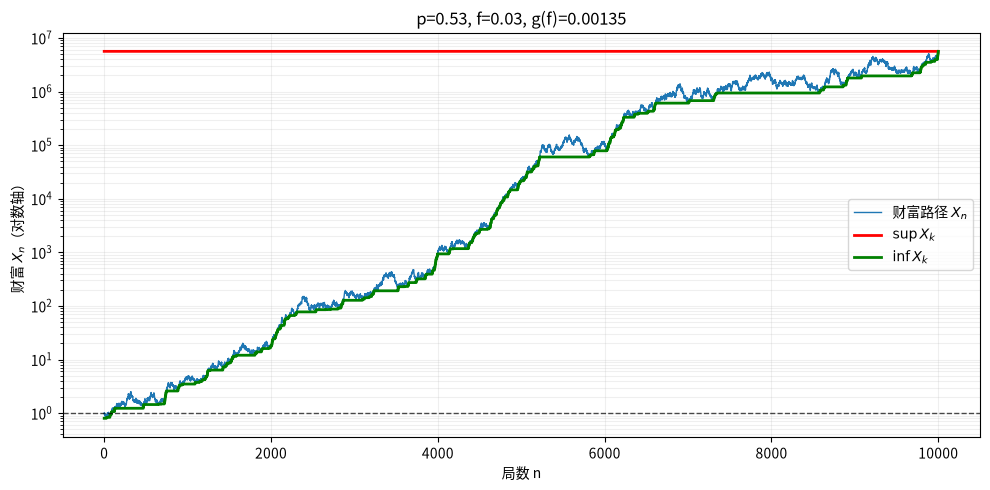

f=0.03, g(f)=0.001350
最终财富 X_n = 5.632078e+06
lim inf = 5.632078e+06
lim sup = 5.632078e+06


(array([1.00000000e+00, 9.70000000e-01, 9.99100000e-01, ...,
        5.30877372e+06, 5.46803693e+06, 5.63207804e+06], shape=(10001,)),
 array([8.01461695e-01, 8.01461695e-01, 8.01461695e-01, ...,
        5.30877372e+06, 5.46803693e+06, 5.63207804e+06], shape=(10001,)),
 array([5632078.03712579, 5632078.03712579, 5632078.03712579, ...,
        5632078.03712579, 5632078.03712579, 5632078.03712579],
       shape=(10001,)))

In [6]:
plot_f(0.03)

### Example 3.2：$f=0.15$


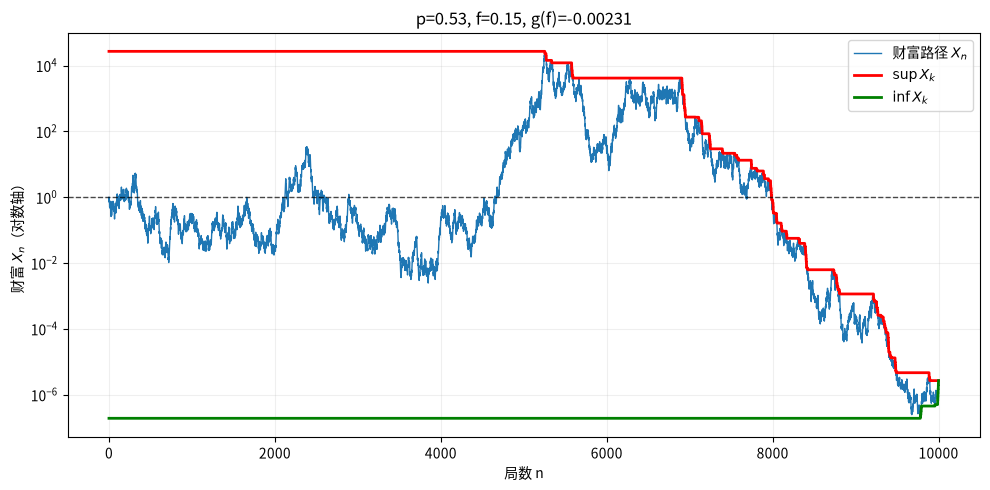

f=0.15, g(f)=-0.002310
最终财富 X_n = 2.697664e-06
lim inf = 2.697664e-06
lim sup = 2.697664e-06


(array([1.00000000e+00, 8.50000000e-01, 9.77500000e-01, ...,
        2.03982142e-06, 2.34579464e-06, 2.69766383e-06], shape=(10001,)),
 array([1.93375751e-07, 1.93375751e-07, 1.93375751e-07, ...,
        2.03982142e-06, 2.34579464e-06, 2.69766383e-06], shape=(10001,)),
 array([2.70866201e+04, 2.70866201e+04, 2.70866201e+04, ...,
        2.69766383e-06, 2.69766383e-06, 2.69766383e-06], shape=(10001,)))

In [7]:
plot_f(0.15)

### Example 3.3：$f=f_c\approx 0.1197$


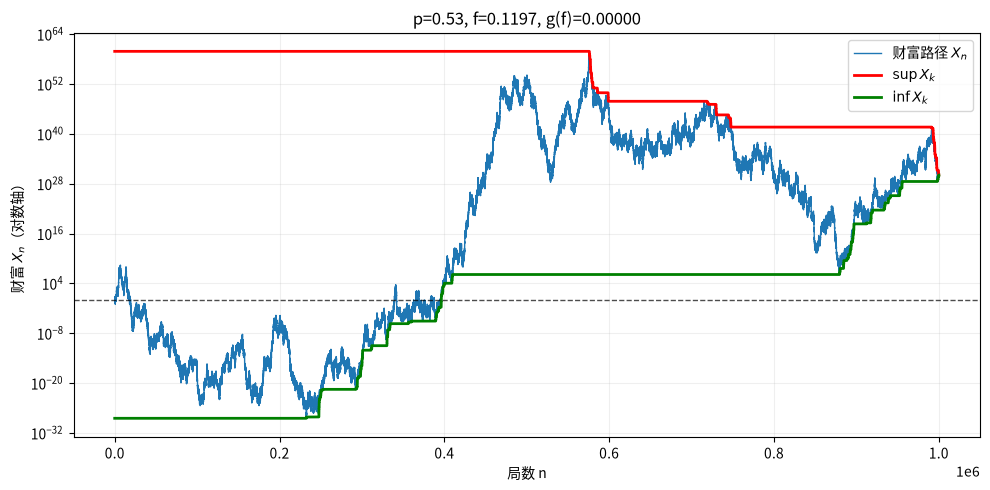

f=0.1197, g(f)=0.000001
最终财富 X_n = 1.240370e+30
lim inf = 1.240370e+30
lim sup = 1.240370e+30


(array([1.00000000e+00, 8.80300000e-01, 9.85671910e-01, ...,
        1.60062591e+30, 1.40903099e+30, 1.24036998e+30], shape=(1000001,)),
 array([3.33708471e-29, 3.33708471e-29, 3.33708471e-29, ...,
        1.24036998e+30, 1.24036998e+30, 1.24036998e+30], shape=(1000001,)),
 array([7.12050213e+59, 7.12050213e+59, 7.12050213e+59, ...,
        1.60062591e+30, 1.40903099e+30, 1.24036998e+30], shape=(1000001,)))

In [8]:
plot_f(F_C, n=1_000_000)


### Example 3.4：同一串输赢

$\Phi^*$ 每局押当前财富的 $f^*=0.06$。对照本质不同的策略：固定比例 $f=0.03$。两条路径共用 seed 42 的同一串输赢，画在同一张对数轴上。


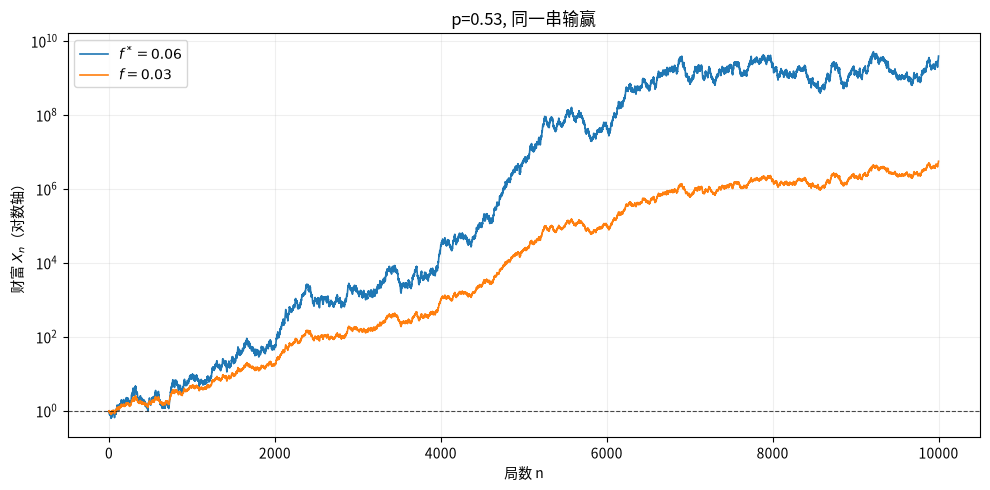

In [9]:
w_star = simulate(F_STAR)
w_small = simulate(0.03)
t = np.arange(len(w_star))

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(t, w_star, color="C0", lw=1.2, label=r"$f^*=0.06$")
ax.plot(t, w_small, color="C1", lw=1.2, label=r"$f=0.03$")
ax.set_yscale("log")
ax.axhline(X0, color="black", ls="--", lw=0.8, alpha=0.7)
ax.set_xlabel("局数 n")
ax.set_ylabel(r"财富 $X_n$（对数轴）")
ax.set_title(f"p={P}, 同一串输赢")
ax.legend(loc="best")
ax.grid(alpha=0.2, which="both")
fig.tight_layout()
plt.show()


### Example 3.5：到达目标的期望局数

Kelly 每局押 $f^*$。期望局数约为 $\ln(C/X_0)/g(f^*)$。$g(f^*)\approx 0.001801$ 时，赚 5% 约 27 局，赚 10% 约 53 局，翻倍约 385 局，翻 10 倍约 1278 局。今晚只有几十局，目标定在几个百分点；能打几千局，翻倍才是一直押 $f^*$ 该做的事。

对照策略平常仍押 $f^*$，但若一把赢就能到目标 $C$，就只押刚好到 $C$ 的金额。下图是两者期望局数之比，目标变远时趋于 1。


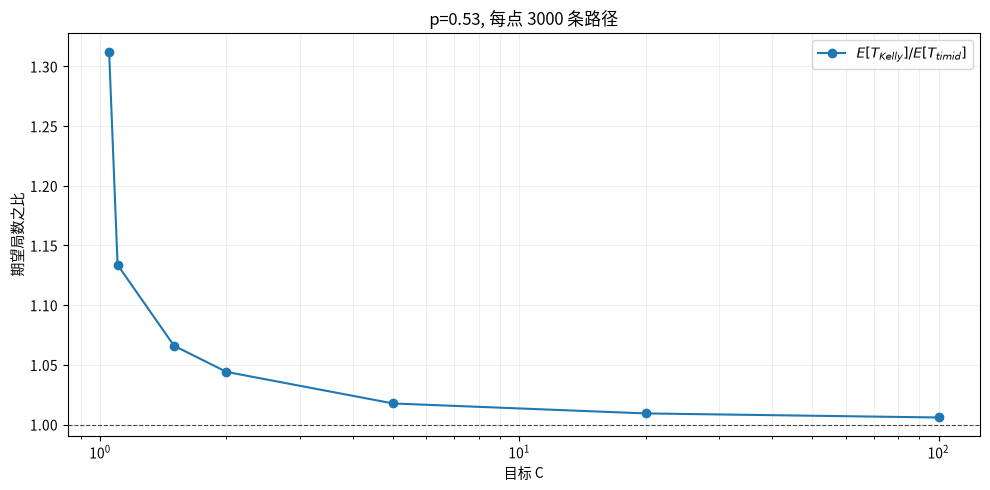

C=   1.05  Kelly=    39.5  timid=    30.1  比值=1.312
C=   1.10  Kelly=    66.3  timid=    58.5  比值=1.134
C=   1.50  Kelly=   232.3  timid=   218.0  比值=1.066
C=   2.00  Kelly=   392.2  timid=   375.6  比值=1.044
C=   5.00  Kelly=   892.5  timid=   877.1  比值=1.018
C=  20.00  Kelly=  1650.3  timid=  1635.1  比值=1.009
C= 100.00  Kelly=  2524.9  timid=  2510.1  比值=1.006


In [10]:
def hitting_time_kelly(rng, C, f=F_STAR, p=P, x0=X0, n_max=100_000):
    if not (0.0 < f < 1.0):
        raise ValueError("偶数赔率下需要 0 < f < 1")
    x = x0
    for n in range(1, n_max + 1):
        x *= (1.0 + f) if rng.random() < p else (1.0 - f)
        if x >= C:
            return n
    return n_max


def hitting_time_timid(rng, C, f=F_STAR, p=P, x0=X0, n_max=100_000):
    if not (0.0 < f < 1.0):
        raise ValueError("偶数赔率下需要 0 < f < 1")
    x = x0
    for n in range(1, n_max + 1):
        b = min(f * x, C - x)
        x = x + b if rng.random() < p else x - b
        if x >= C:
            return n
    return n_max


def mean_hitting_time(T_fn, C, n_paths=3000, seed=SEED):
    rng = np.random.default_rng(seed)
    return float(np.mean([T_fn(rng, C) for _ in range(n_paths)]))


Cs = np.array([1.05, 1.1, 1.5, 2.0, 5.0, 20.0, 100.0])
E_kelly = np.array([mean_hitting_time(hitting_time_kelly, C) for C in Cs])
E_timid = np.array([mean_hitting_time(hitting_time_timid, C) for C in Cs])
ratio = E_kelly / E_timid

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(Cs, ratio, "o-", color="C0", label=r"$E[T_{Kelly}]/E[T_{timid}]$")
ax.axhline(1.0, color="black", ls="--", lw=0.8, alpha=0.7)
ax.set_xscale("log")
ax.set_xlabel("目标 C")
ax.set_ylabel("期望局数之比")
ax.set_title(f"p={P}, 每点 {3000} 条路径")
ax.legend(loc="best")
ax.grid(alpha=0.2, which="both")
fig.tight_layout()
plt.show()

for C, ek, et in zip(Cs, E_kelly, E_timid):
    print(f"C={C:7.2f}  Kelly={ek:8.1f}  timid={et:8.1f}  比值={ek/et:.3f}")


### Example 3.6：胜率每局可变

计牌式设定：冷门 $p=0.49$（无优势，不押），热门 $p=0.55$（优势，每次押仓位的 $f^*=0.10$），各 50 局轮换。同一串输赢下对比两条路径：
- 每局按 $f_i^*=p_i-q_i$ 调整
- 全程用平均胜率算出的固定 $f$


In [11]:
n = 2000
rng = np.random.default_rng(SEED)
block = 50

p_seq = np.where((np.arange(n) // block) % 2 == 0, 0.49, 0.55)  # 冷门 0.49 / 热门 0.55 轮换
wins = rng.random(n) < p_seq

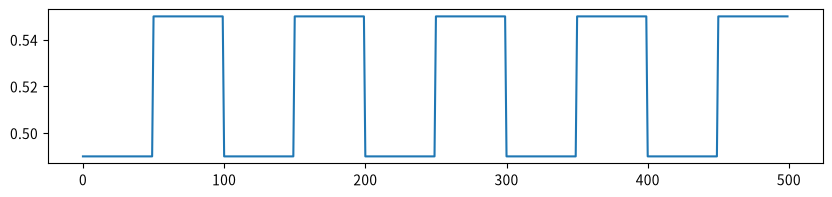

In [12]:
plt.figure(figsize=(10,2))
plt.plot(p_seq[:500])
plt.show()

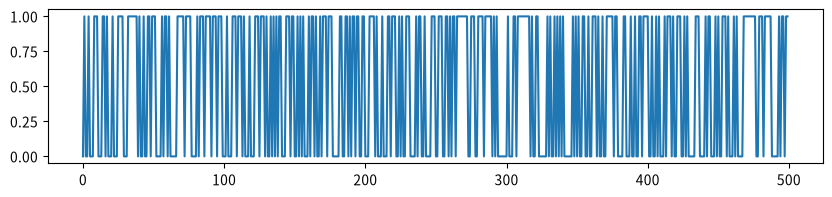

In [13]:
plt.figure(figsize=(10,2))
plt.plot(wins[:500])
plt.show()

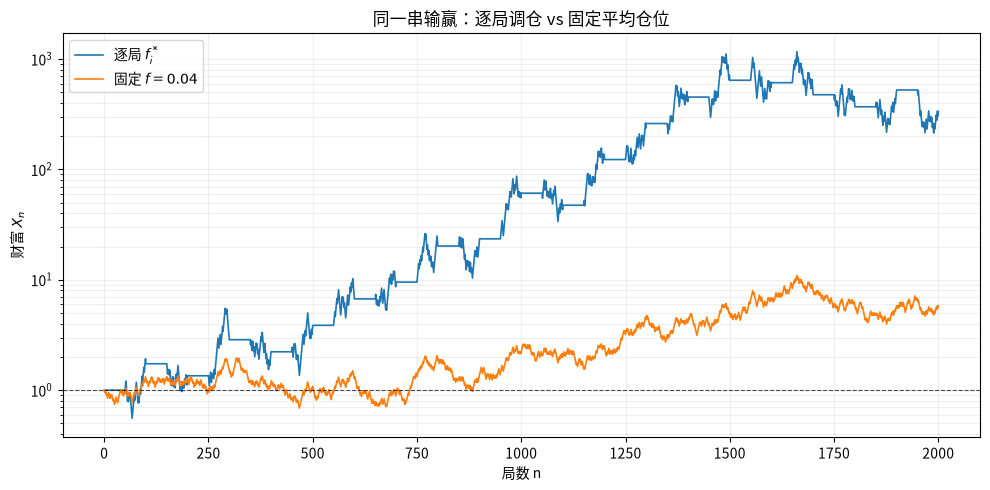

平均 p=0.52, 固定 f=0.04. 终局财富:逐局=3.34e+02, 固定=5.82e+00, 比值=57.43


In [14]:
f_adapt = np.maximum(0.0, 2.0 * p_seq - 1.0)  # f_i* = p_i - q_i；无优势时为 0
p_avg = float(p_seq.mean())
f_fixed_val = max(0.0, 2.0 * p_avg - 1.0)
f_fixed = np.full(n, f_fixed_val)

w_adapt = np.empty(n + 1, dtype=float)
w_fixed = np.empty(n + 1, dtype=float)
w_adapt[0] = w_fixed[0] = X0
for i in range(n):
    fa, ff = f_adapt[i], f_fixed[i]
    if wins[i]:
        w_adapt[i + 1] = w_adapt[i] * (1.0 + fa)
        w_fixed[i + 1] = w_fixed[i] * (1.0 + ff)
    else:
        w_adapt[i + 1] = w_adapt[i] * (1.0 - fa)
        w_fixed[i + 1] = w_fixed[i] * (1.0 - ff)

t = np.arange(n + 1)
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(t, w_adapt, color="C0", lw=1.2, label=rf"逐局 $f_i^*$")
ax.plot(t, w_fixed, color="C1", lw=1.2, label=rf"固定 $f={f_fixed_val:.2f}$")
ax.set_yscale("log")
ax.axhline(X0, color="black", ls="--", lw=0.8, alpha=0.7)
ax.set_xlabel("局数 n")
ax.set_ylabel(r"财富 $X_n$")
ax.set_title("同一串输赢：逐局调仓 vs 固定平均仓位")
ax.legend(loc="best")
ax.grid(alpha=0.2, which="both")
fig.tight_layout()
plt.show()
print(
    f"平均 p={p_avg:.2f}, 固定 f={f_fixed_val:.2f}. "
    f"终局财富:逐局={w_adapt[-1]:.2e}, 固定={w_fixed[-1]:.2e}, "
    f"比值={w_adapt[-1]/w_fixed[-1]:.2f}"
)

### Example 3.7：赔率不对称（Thorp Example 2.1）

一般公式：赢时净得 $b$、输时损失 $a$，则 $f^*=(bp-aq)/(ab)$，且 $0<f<1/a$。

下图画三条 $g(f)$，方便对照：

- 蓝线：$a=b=1$，$p=0.53$。这是笔记前半用的偶数赔率，应得到 $f^*=p-q=0.06$。
- 橙线：$a=2$，$b=3$，$p=0.55$。输的时候亏得比押注多（$a>1$），检验一般公式，应得 $f^*=0.125$。
- 绿线：$a=1$，$b=10/11$，$p=0.55$。这是 Hung §4 仿真用的赔率：赢只净赚约 $0.909$，不是 1 比 1；此时 $f^*=0.055$。


p=0.53, a=1.0, b=1.0000, m=0.0600, f*=0.0600, g(f*)=0.001801, 定义域 (0, 1.0000)
p=0.55, a=2.0, b=3.0000, m=0.7500, f*=0.1250, g(f*)=0.045693, 定义域 (0, 0.5000)
p=0.55, a=1.0, b=0.9091, m=0.0500, f*=0.0550, g(f*)=0.001378, 定义域 (0, 1.0000)


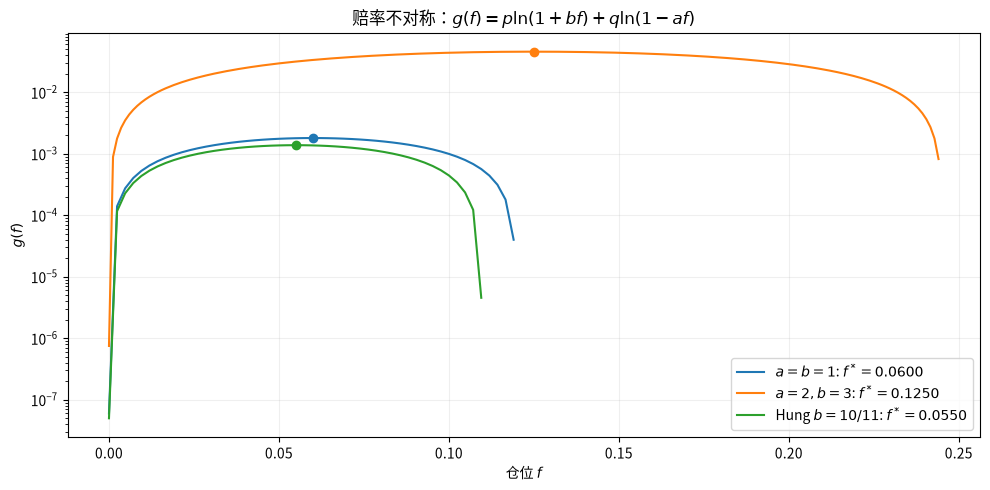

In [15]:
def g_ab(f, p, a, b):
    q = 1.0 - p
    return p * np.log(1.0 + b * f) + q * np.log(1.0 - a * f)


def f_star_ab(p, a, b):
    q = 1.0 - p
    m = b * p - a * q
    return m / (a * b)


cases = [
    dict(name=r"$a=b=1$", p=0.53, a=1.0, b=1.0),
    dict(name=r"$a=2,b=3$", p=0.55, a=2.0, b=3.0),
    dict(name=r"Hung $b=10/11$", p=0.55, a=1.0, b=10.0 / 11.0),
]

fig, ax = plt.subplots(figsize=(10, 5))
for i, c in enumerate(cases):
    p_, a, b = c["p"], c["a"], c["b"]
    m = b * p_ - a * (1.0 - p_)
    fstar = f_star_ab(p_, a, b)
    f_max = 1.0 / a
    fs = np.linspace(1e-6, 0.95 * f_max, 400)
    gs = g_ab(fs, p_, a, b)
    gstar = g_ab(fstar, p_, a, b)
    color = f"C{i}"
    mask = gs > 0
    ax.plot(fs[mask], gs[mask], color=color, lw=1.5, label=rf'{c["name"]}: $f^*={fstar:.4f}$')
    if gstar > 0:
        ax.scatter([fstar], [gstar], color=color, zorder=3)
    print(
        f'p={p_}, a={a}, b={b:.4f}, m={m:.4f}, '
        f'f*={fstar:.4f}, g(f*)={gstar:.6f}, 定义域 (0, {f_max:.4f})'
    )

ax.set_xlabel(r"仓位 $f$")
ax.set_ylabel(r"$g(f)$")
ax.set_yscale("log")
ax.set_title(r"赔率不对称：$g(f)=p\ln(1+bf)+q\ln(1-af)$")
ax.legend(loc="best")
ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()


### Example 4.1：标普 500 连续近似（Thorp §7.2）

Thorp 粗估 $m=0.11$，$s=0.15$，$r=0.06$。对照 $f=1$ 与借款利率 $r_b=0.08$。$f\le 1$ 用国债 $r$，$f>1$ 用借款 $r_b$。

黑线是可行分段 $g$。左图 $f^*(r_b)>1$ 借钱自洽；右图把 $m$ 降到 $0.09$，出现 $f^*(r)>1>f^*(r_b)$，最优变为 $f^*=1$。


m=0.11: f_r=2.22, f_rb=1.33 → f_opt=1.33（按 $r_b$）
m=0.09: f_r=1.33, f_rb=0.44 → f_opt=1.00（按最优仓位 $f^*=1$）


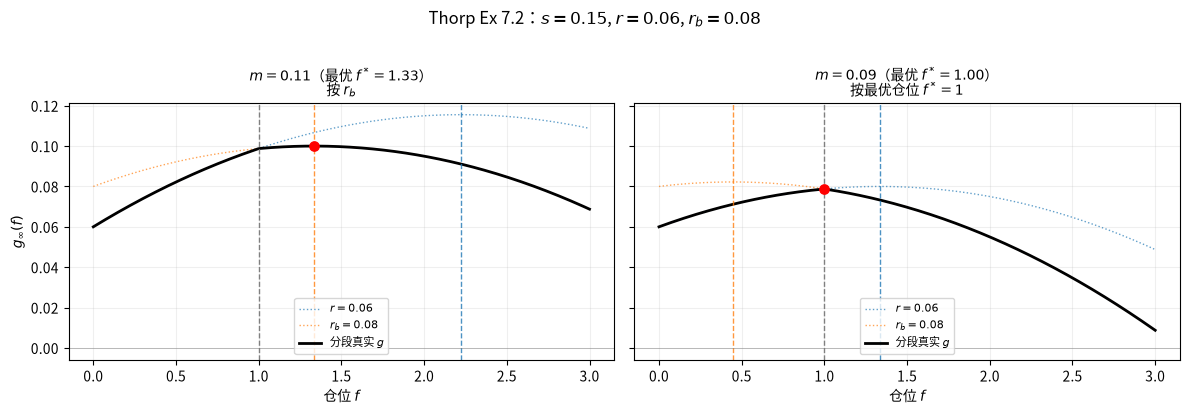

In [16]:
def g_infty(f, m, s, r):
    return r + f * (m - r) - 0.5 * s**2 * f**2


def f_star(m, s, r):
    return (m - r) / s**2


def g_piecewise(f, m, s, r, r_b):
    f = np.asarray(f, dtype=float)
    out = np.empty_like(f)
    use_r = f <= 1.0  # 不加杠杆：用 r；加杠杆：用 r_b
    out[use_r] = g_infty(f[use_r], m, s, r)
    out[~use_r] = g_infty(f[~use_r], m, s, r_b)
    return out


m1, m2, s, r, r_b = 0.11, 0.09, 0.15, 0.06, 0.08
cases = [(m1, rf"$m={m1}$"), (m2, rf"$m={m2}$")]

fs = np.linspace(0.0, 3.0, 401)
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

for ax, (m_i, title) in zip(axes, cases):
    f_r, f_rb = f_star(m_i, s, r), f_star(m_i, s, r_b)
    if f_rb >= 1:
        f_opt, note = f_rb, r"按 $r_b$"
    elif f_r <= 1:
        f_opt, note = f_r, r"按 $r$"
    else:
        f_opt, note = 1.0, r"按最优仓位 $f^*=1$"

    print(f"m={m_i}: f_r={f_r:.2f}, f_rb={f_rb:.2f} → f_opt={f_opt:.2f}（{note}）")

    ax.plot(fs, g_infty(fs, m_i, s, r), color="C0", ls=":", lw=1, alpha=0.7, label=rf"$r={r}$")
    ax.plot(fs, g_infty(fs, m_i, s, r_b), color="C1", ls=":", lw=1, alpha=0.7, label=rf"$r_b={r_b}$")
    ax.plot(fs, g_piecewise(fs, m_i, s, r, r_b), color="black", lw=2, label="分段真实 $g$")
    ax.axvline(1.0, color="gray", ls="--", lw=1)
    ax.axvline(f_r, color="C0", ls="--", lw=1, alpha=0.8)
    ax.axvline(f_rb, color="C1", ls="--", lw=1, alpha=0.8)
    ax.scatter([f_opt], [float(g_piecewise(f_opt, m_i, s, r, r_b))], color="red", zorder=5, s=45)
    ax.axhline(0.0, color="gray", lw=0.7, alpha=0.5)
    ax.set_title(title + rf"（最优 $f^*={f_opt:.2f}$）" + "\n" + note, fontsize=10)
    ax.set_xlabel(r"仓位 $f$")
    ax.grid(alpha=0.2)
    ax.legend(loc="lower center", fontsize=8)

axes[0].set_ylabel(r"$g_\infty(f)$")
fig.suptitle(rf"Thorp Ex 7.2：$s={s}$, $r={r}$, $r_b={r_b}$", y=1.02)
fig.tight_layout()
plt.show()


### Example 4.2：从日收益估计年化 $m$，$s$

假设日简单收益的均值与波动为日均 $0.0004$、日波动 $0.01$，生成一年样本后按 $252$ 与 $\sqrt{252}$ 计算年化。
再比较三种口径：简单收益、对数收益、对数收益加回 $s^2/2$，来体现用错收益率口径对 $f^*$ 的影响。


In [17]:
# 简单收益
m_d, s_d = 0.0004, 0.01  # 日均约 0.04%，日波动 1%
r = 0.06
n_days = 252 
rng = np.random.default_rng(SEED)

X = rng.normal(m_d, s_d, n_days)
X = (X - X.mean()) / X.std(ddof=1) * s_d + m_d  # 对齐给定日均值/波动，只看口径
logX = np.log(1.0 + X)

# 真值：由给定日参数直接年化，作为对照基准
m_true = m_d * 252
s_true = s_d * np.sqrt(252)
f_true = (m_true - r) / s_true**2

# 简单收益口径：公式里的 m 就是 E[X]；样本已对齐，应与真值一致
m_simple = X.mean() * 252
s_hat = X.std(ddof=1) * np.sqrt(252)
f_simple = (m_simple - r) / s_hat**2

# 对数收益口径：E[ln(1+X)] ≈ m - s²/2；若误当 m 用，会偏低，f* 也偏低
m_log = logX.mean() * 252
f_log = (m_log - r) / s_hat**2

# 对数 + s²/2：补回波动拖累，应回到简单收益 / 真值附近
m_adj = m_log + 0.5 * s_hat**2
f_adj = (m_adj - r) / s_hat**2

print(f"日参数: m_d={m_d}, s_d={s_d}, r={r}")
print(f"对数收益理论值约 m-s²/2 = {m_true - 0.5 * s_true**2:.4f}")
print()
print(f"{'口径':<12}{'年化 m':>10}{'年化 s':>10}{'f*':>8}")
print("-" * 50)
for name, m_i, s_i, f_i in [
    ("真值", m_true, s_true, f_true),
    ("简单收益", m_simple, s_hat, f_simple),
    ("对数收益", m_log, s_hat, f_log),
    ("对数+s²/2", m_adj, s_hat, f_adj),
]:
    print(f"{name:<12}{m_i:10.4f}{s_i:10.4f}{f_i:8.2f}")


日参数: m_d=0.0004, s_d=0.01, r=0.06
对数收益理论值约 m-s²/2 = 0.0882

口径                年化 m      年化 s      f*
--------------------------------------------------
真值              0.1008    0.1587    1.62
简单收益            0.1008    0.1587    1.62
对数收益            0.0883    0.1587    1.12
对数+s²/2         0.1009    0.1587    1.62


### Example 5.1：平均终值 vs 几何平均

偶数赔率，$p=0.6$（$f^*=0.2$），下 10 局，本金 1。蒙特卡罗仿真 1000 条路径，比较 $f=0.2,\,0.5,\,0.8,\,1.0$ 的样本平均终值、几何平均、中位数和最后亏钱的比例，并与二项分布的精确值对照。


In [18]:
from math import comb
import pandas as pd

In [19]:
# 偶数赔率，胜率 p，下 n 局，本金 1；
# Kelly 仓位 f* = p - q = 0.2
p, n, n_paths = 0.6, 10, 1000
fs = (0.2, 0.5, 0.8, 1.0)

In [20]:
# 精确解：终值只取决于赢了几局 k，与输赢顺序无关
# ks = 0, 1, ..., n，共 n+1 种结局
ks = np.arange(n + 1)
ks

array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10])

In [21]:
# 排法数：n 局里恰好赢 k 局，有多少种不同的输赢顺序，即组合数 C(n, k)
n_orders = np.array([comb(n, k) for k in ks])
n_orders

array([  1,  10,  45, 120, 210, 252, 210, 120,  45,  10,   1])

In [22]:
# 某一种指定顺序（赢 k 局、输 n-k 局）出现的概率
# 每局独立，赢乘 p、输乘 1-p；
# 同一个 k 下每种顺序的概率都一样
prob_one_order = p**ks * (1 - p) ** (n - ks)
prob_one_order

array([0.00010486, 0.00015729, 0.00023593, 0.00035389, 0.00053084,
       0.00079626, 0.00119439, 0.00179159, 0.00268739, 0.00403108,
       0.00604662])

In [23]:
# 赢 k 局的概率 = 排法数 × 单一顺序的概率（二项分布）；
# n+1 个数加起来等于 1
prob_k = n_orders * prob_one_order
prob_k

array([1.04857600e-04, 1.57286400e-03, 1.06168320e-02, 4.24673280e-02,
       1.11476736e-01, 2.00658125e-01, 2.50822656e-01, 2.14990848e-01,
       1.20932352e-01, 4.03107840e-02, 6.04661760e-03])

In [24]:
prob_k.sum()

np.float64(1.0)

In [25]:
def exact_stats(f):
    """理论算术平均、理论几何平均、理论亏钱概率。"""
    x_ks = (1 + f) ** ks * (1 - f) ** (n - ks)  # 赢 k 局时的终值，k 取遍 ks
    mean = prob_k @ x_ks
    with np.errstate(divide="ignore"):  # f=1 时部分终值为 0，ln 0 = -inf，几何平均为 0
        geo = np.exp(prob_k @ np.log(x_ks))  # exp(E[ln X]) = exp(n g(f))
    lose = prob_k[x_ks < 1].sum()
    return mean, geo, lose


def simulate_stats(f, win):
    """各条路径终值，以及仿真算术平均、仿真几何平均、仿真亏钱比例。"""
    wealth = np.where(win, 1 + f, 1 - f).prod(axis=1)
    mean = wealth.mean()
    with np.errstate(divide="ignore"):  # f=1 时输一局即归零，ln 0 = -inf，几何平均为 0
        geo = np.exp(np.log(wealth).mean())
    lose = (wealth < 1).mean()
    return wealth, mean, geo, lose


def as_pct(df, cols):
    """把比例列转成百分比字符串；须在 round 之前调用，否则精度先被截掉。"""
    df[cols] = df[cols].apply(lambda s: s.map("{:.1%}".format))
    return df

In [26]:
# 一次仿真对照精确值；所有 f 共用同一串输赢，差别只来自仓位
win = np.random.default_rng(SEED).random((n_paths, n)) < p
win

array([[False,  True, False, ..., False,  True,  True],
       [ True, False, False, ...,  True, False, False],
       [False,  True, False, ...,  True,  True, False],
       ...,
       [False,  True, False, ..., False,  True,  True],
       [ True,  True, False, ..., False,  True,  True],
       [ True,  True,  True, ...,  True,  True,  True]], shape=(1000, 10))

In [27]:
rows = []
for f in fs:
    mean_exact, geo_exact, lose_exact = exact_stats(f)
    wealth, mean_sim, geo_sim, lose_sim = simulate_stats(f, win)
    rows.append({
        "f": f,
        "理论算数平均": mean_exact,    # 二项概率加权：prob_k @ x_ks
        "仿真算数平均": mean_sim,      # 1000 条路径终值的算术平均
        "理论几何平均": geo_exact,      # exp(E[ln X]) = exp(n g(f))
        "仿真几何平均": geo_sim,        # 1000 条路径终值的几何平均
        "中位数": np.median(wealth),
        "仿真亏钱": lose_sim,
        "理论亏钱": lose_exact,
    })
table = pd.DataFrame(rows).set_index("f")
display(as_pct(table, ["仿真亏钱", "理论亏钱"]).round(2))

,理论算数平均,仿真算数平均,理论几何平均,仿真几何平均,中位数,仿真亏钱,理论亏钱
f,,,,,,,
0.2,1.48,1.53,1.22,1.25,1.22,35.3%,36.7%
0.5,2.59,2.91,0.71,0.75,0.71,59.5%,61.8%
0.8,4.41,5.74,0.05,0.06,0.05,82.2%,83.3%
1.0,6.19,9.22,0.00,0.00,0.00,99.1%,99.4%


按算术平均挑选仓位，理论值与仿真值给出同一排序：$f$ 越大越好，全押最优。然而全押时 99.4% 的路径归零，6.19 的期望完全由概率约 0.6% 的全胜路径撑起。终值分布右偏，仿真算术平均因此偏高，且 $f$ 越大偏得越多。更根本的是，它所逼近的期望本身随 $f$ 单调递增，样本再多，也只会更确定地指向全押。

几何平均给出相反的排序。理论值 $\exp(n\,g(f))$ 在 $f^*=0.2$ 处取得最大值 1.22，此后迅速下降，全押为 0。仿真值与理论值相差不过 0.01 至 0.04。中位数则与理论值完全重合：终值随赢局数 $K$ 单调递增，几何平均对应 $K$ 的均值，中位数对应 $K$ 的中位数，而 $K\sim\mathrm{Binomial}(10,0.6)$ 的均值与中位数同为 6。几何平均刻画的，正是一条典型路径的归宿。

因此，以蒙特卡罗比较仓位，应以几何平均或中位数为准，而非终值的算术平均。
